# Settings

In [452]:
using_simulation_data = True
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_rf/compare_sims/0001_params.json"

#angles to study
examine_all_angles = False
angles_to_study = [-6, -3, 0, 3, 6]

bf_data_path = '/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/compare_sims/0001_bf__angles.npy'

# Imports

In [453]:
import numpy as np
import matplotlib.pyplot as plt
import json

# Import parameters

In [454]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [455]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"]

    return params

In [456]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = 1500 #speed of sound

# Load BF data

In [457]:
bf_matrices = np.load(bf_data_path)

print(bf_matrices.shape)
if bf_matrices.ndim == 4:
    bf_matrices = np.reshape(bf_matrices, (bf_matrices.shape[0], bf_matrices.shape[1], bf_matrices.shape[2] * bf_matrices.shape[3]))

tmp_matrix = np.zeros((bf_matrices.shape[0], bf_matrices.shape[1], len(angles_to_study)))

for i in range(len(angles_to_study)):
    tmp_matrix[:, :, i] = bf_matrices[:, :, np.where(np.array(params["rf"]["angles"]) == angles_to_study[i])[0][0]]

(96, 128, 5, 1)


In [458]:
bf_matrices.shape

(96, 128, 5)

In [459]:
if not examine_all_angles:
    bf_matrices = tmp_matrix

# Display angles

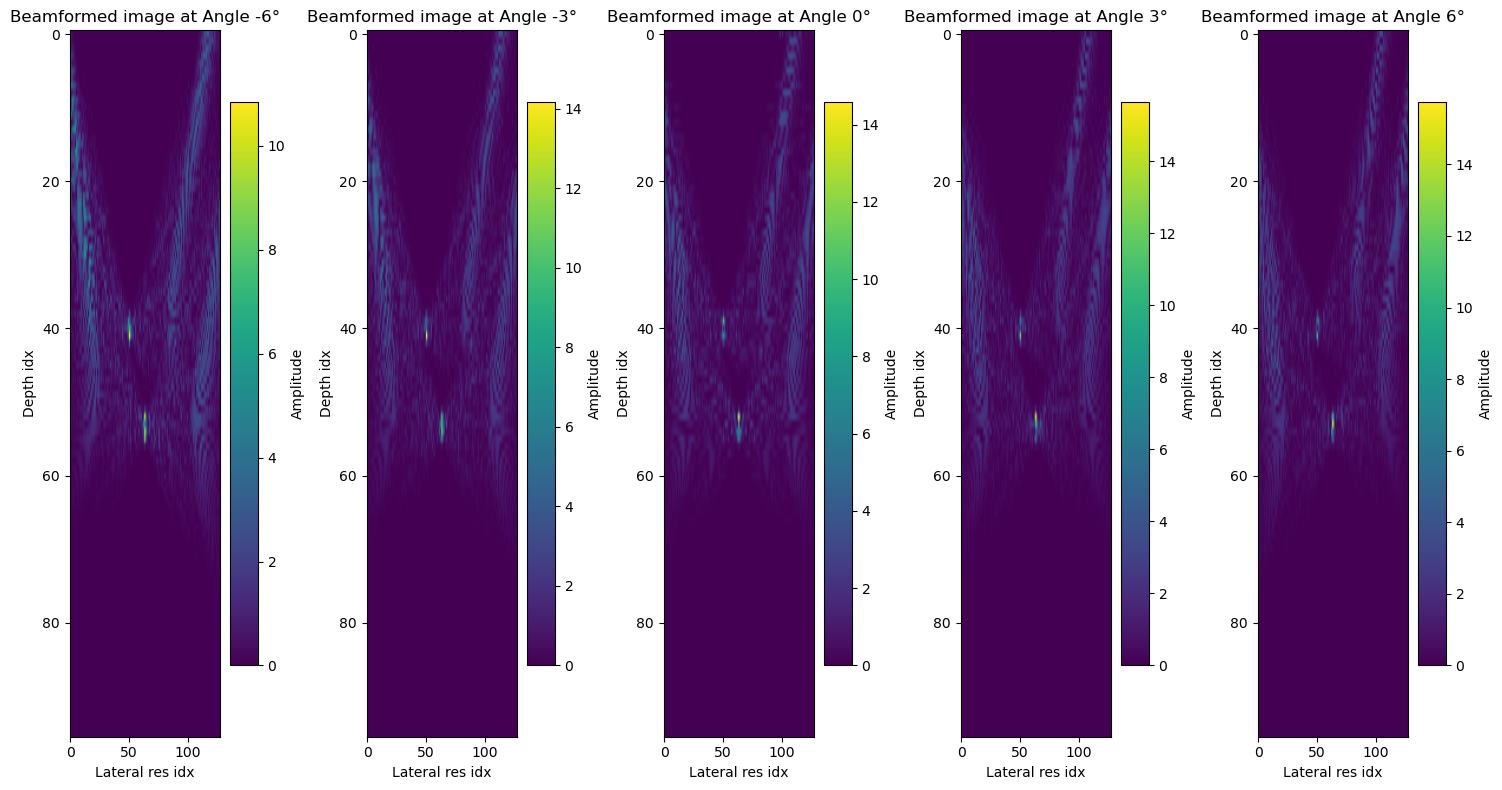

In [460]:

num_angles = bf_matrices.shape[2]
fig, axes = plt.subplots(nrows=1, ncols=num_angles, figsize=(15,8))

if num_angles == 1:
    axes = [axes]

for i in range(num_angles):
    im = axes[i].imshow(np.abs(bf_matrices[:,:,i]), aspect='auto', cmap='viridis')
    axes[i].set_title(f'Beamformed image at Angle {params["rf"]["angles"][i] if examine_all_angles else angles_to_study[i]}°')
    axes[i].set_xlabel('Lateral res idx')
    axes[i].set_ylabel('Depth idx')
    fig.colorbar(im, ax=axes[i], label='Amplitude')

plt.tight_layout()
plt.show()

# Get most energy axial profile

In [461]:
def extract_highest_value_region_all_angles(bf_matrices, depth_margin=15, lateral_margin=15):
    submatrices = []
    low_row_pos = np.inf
    high_row_pos = -np.inf
    low_col_pos = np.inf
    high_col_pos = -np.inf
    
    for i in range(bf_matrices.shape[2]):
        row, col = np.unravel_index(np.argmax(np.abs(bf_matrices[:,:,i])), bf_matrices[:,:,i].shape)

        if row < low_row_pos:
            low_row_pos = row
        if row > high_row_pos:
            high_row_pos = row
        if col < low_col_pos:
            low_col_pos = col
        if col > high_col_pos:
            high_col_pos = col

    submatrices = bf_matrices[low_row_pos-depth_margin:high_row_pos+depth_margin, low_col_pos-lateral_margin:high_col_pos+lateral_margin, :]
    return submatrices

## Images

Max value at angle -6°: 10.854221840660806
Max value row: 40, col: 15


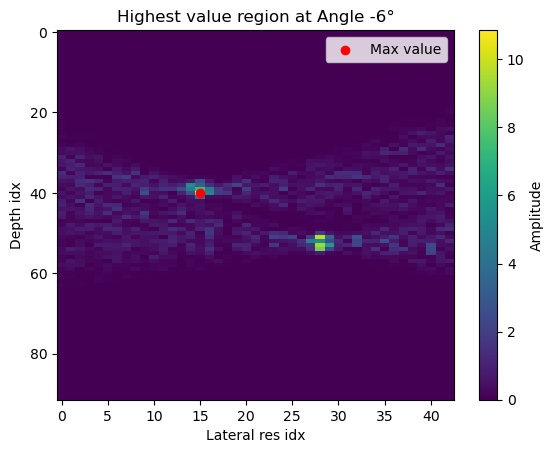

Max value at angle -3°: 14.1772258752313
Max value row: 40, col: 15


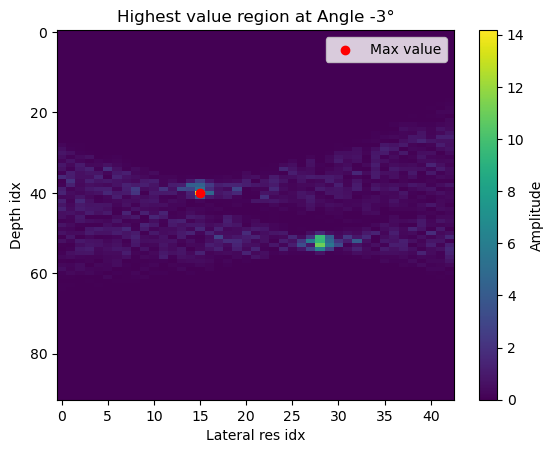

Max value at angle 0°: 14.598544044938212
Max value row: 51, col: 28


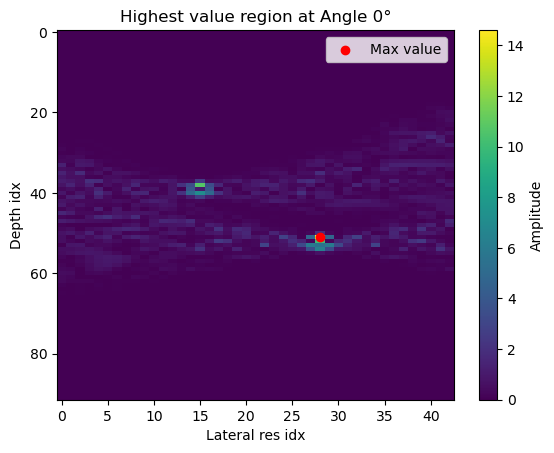

Max value at angle 3°: 15.6501238687564
Max value row: 51, col: 28


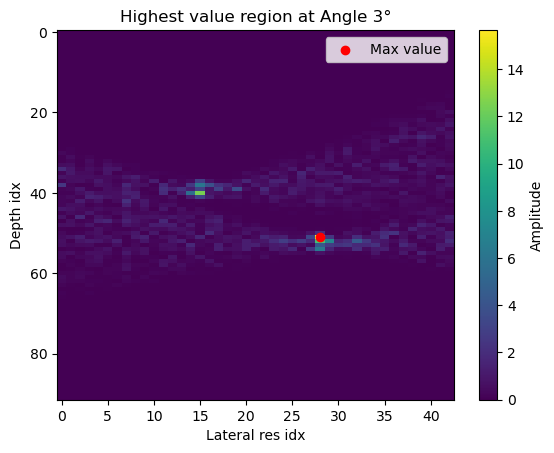

Max value at angle 6°: 15.753074984290748
Max value row: 52, col: 28


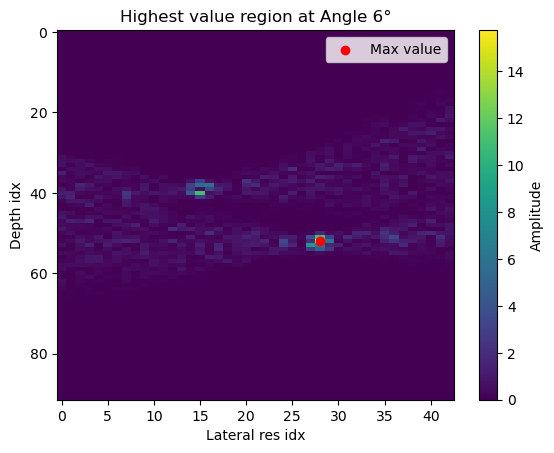

In [462]:
submatrix = extract_highest_value_region_all_angles(np.abs(bf_matrices), depth_margin= 40, lateral_margin= 15)

for i in range(num_angles):
        
    max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(submatrix[:,:,i])), submatrix[:,:,i].shape)
    print(f"Max value at angle {params["rf"]["angles"][i] if examine_all_angles else angles_to_study[i]}°: {submatrix[:,:,i][max_val_row, max_val_col]}")
    print(f"Max value row: {max_val_row}, col: {max_val_col}")
    plt.imshow(submatrix[:,:,i], aspect='auto', cmap='viridis')
    plt.title(f'Highest value region at Angle {params["rf"]["angles"][i] if examine_all_angles else angles_to_study[i]}°')
    plt.xlabel('Lateral res idx')
    plt.ylabel('Depth idx')
    plt.colorbar(label='Amplitude')
    plt.scatter(max_val_col, max_val_row, color='red', label='Max value')
    plt.legend()
    plt.show()

## Curves

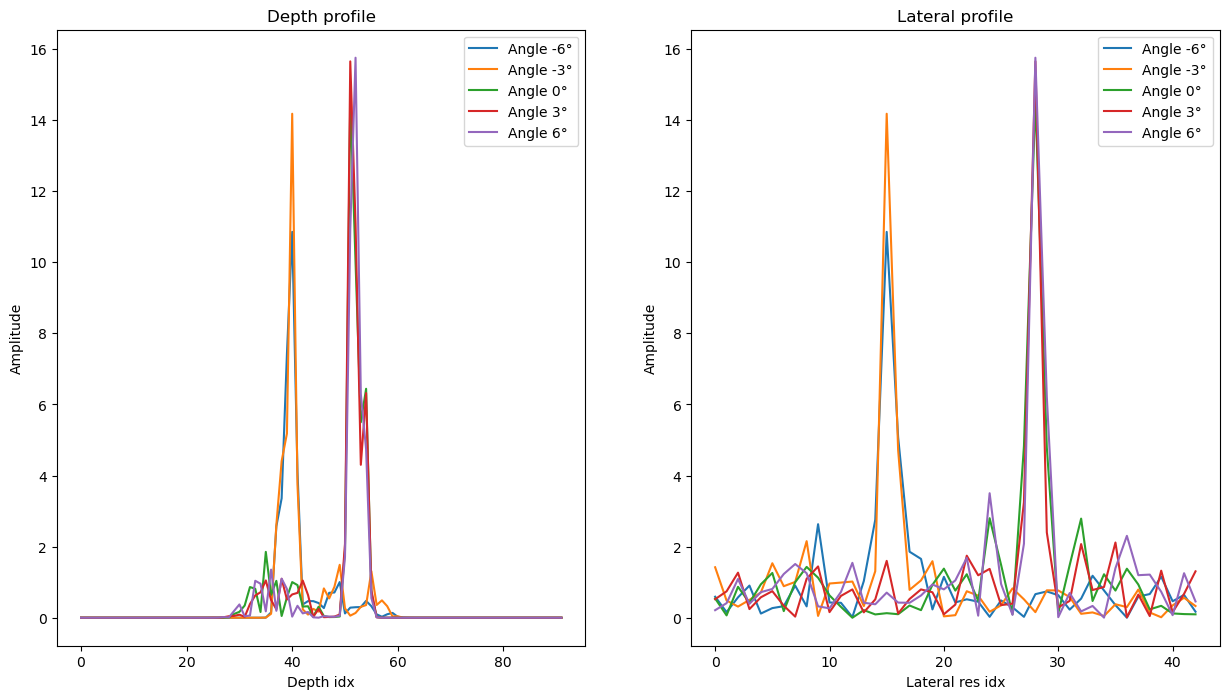

In [463]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,8))

for i in range(submatrix.shape[2]):
    max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(submatrix[:,:,i])), submatrix[:,:,i].shape)
    axes[0].plot(submatrix[:,:,i][:,max_val_col], label=f'Angle {params["rf"]["angles"][i] if examine_all_angles else angles_to_study[i]}°')
    axes[0].set_title('Depth profile')
    axes[0].set_xlabel('Depth idx')
    axes[0].set_ylabel('Amplitude')
    axes[0].legend()

    axes[1].plot(submatrix[:,:,i][max_val_row,:], label=f'Angle {params["rf"]["angles"][i] if examine_all_angles else angles_to_study[i]}°')
    axes[1].set_title('Lateral profile')
    axes[1].set_xlabel('Lateral res idx')
    axes[1].set_ylabel('Amplitude')
    axes[1].legend()

In [477]:
test_bf = bf_matrices[:,:,2:]

In [478]:
bf_matrices_summed = np.sum(test_bf, axis = 2)

In [479]:
bf_matrices_summed.shape

(96, 128)

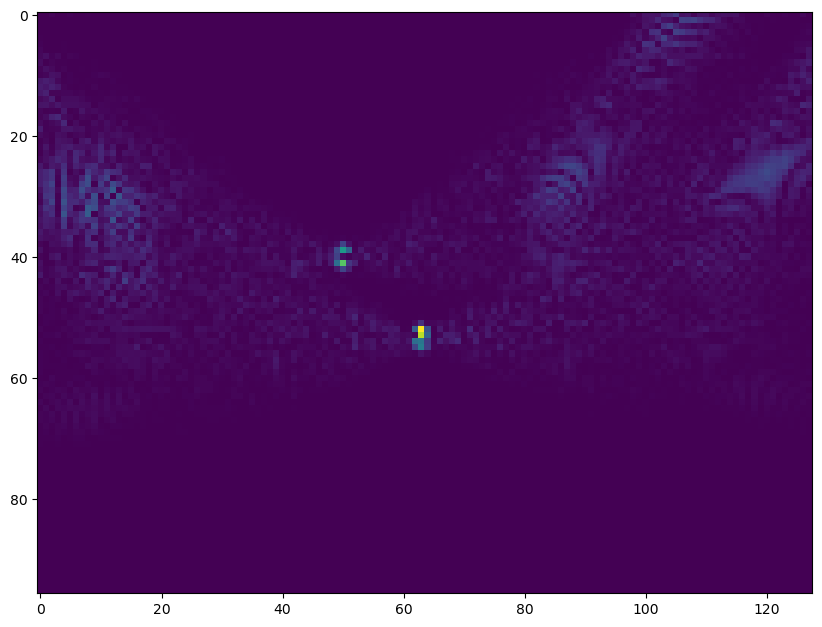

In [480]:
plt.figure(figsize=(10,8))
plt.imshow(np.abs(bf_matrices_summed))